# Médias Móveis

In [1]:
# No Google Colab o Prophet já vem instalado. Em outro ambiente, descomente a linha abaixo:
# !pip install prophet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import logging
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)  # reduz mensagens de log

# https://www.kaggle.com/datasets/rakannimer/air-passengers

df=pd.read_csv("https://raw.githubusercontent.com/celsocrivelaro/simple-datasets/main/AirPassengers.csv")

df

Importing plotly failed. Interactive plots will not work.


,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121
...,...,...
139,1960-08,606
140,1960-09,508
141,1960-10,461
142,1960-11,390


<Axes: xlabel='Month'>

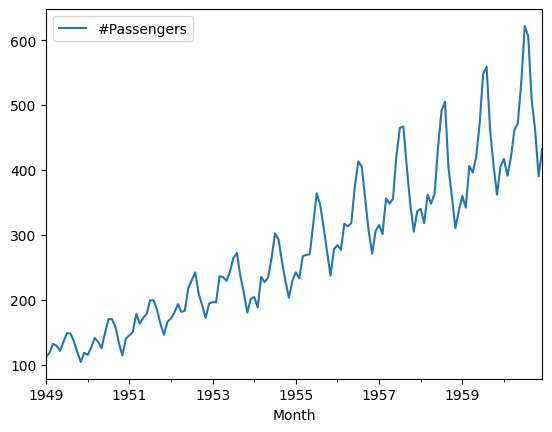

In [2]:
df.set_index('Month',inplace=True)
df.index=pd.to_datetime(df.index)
#drop null values
df.dropna(inplace=True)
df.plot()

A **média móvel** é uma janela que calcula a média dos $N$ últimos valores:

$$\text{MM}_t = \frac{y_t + y_{t-1} + \dots + y_{t-N+1}}{N}$$

- Quanto **maior** o $N$, mais suave é a curva e mais ela reflete a **tendência**.
- Quanto **menor** o $N$, mais a curva acompanha as oscilações de curto prazo, e ainda se vê a **sazonalidade**.
- Com $N = 12$ em dados mensais, cada média cobre exatamente um ano, então a sazonalidade anual se cancela e sobra a tendência.

O **desvio padrão móvel** mostra se a variabilidade da série muda ao longo do tempo. Se ele cresce junto com o nível da série, é um sinal de sazonalidade **multiplicativa**.

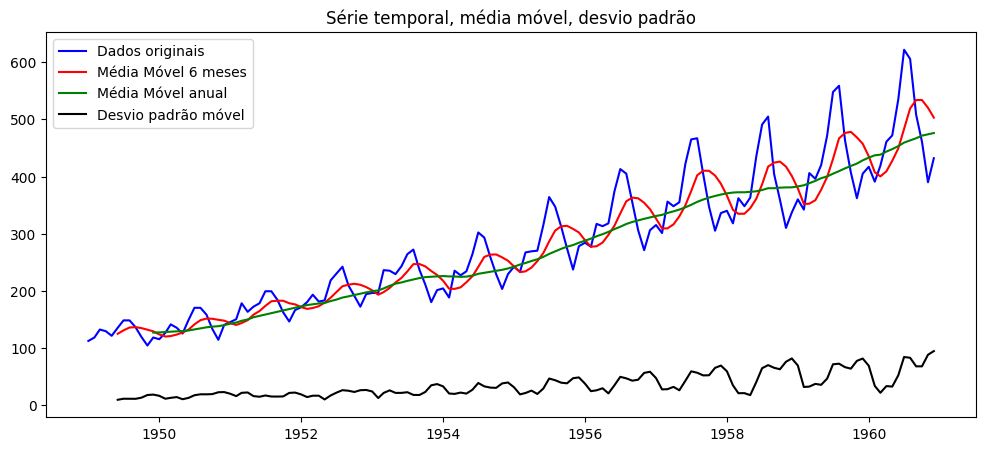

In [3]:
rolling_mean_9 = df.rolling(9).mean()
rolling_mean = df.rolling(6).mean()
rolling_mean_month = df.rolling(12).mean()
rolling_std = df.rolling(6).std()

plt.figure(figsize=(12, 5))
plt.plot(df, color="blue", label="Dados originais")
#plt.plot(rolling_mean_9, color="purple", label="Média Móvel 9 meses")
plt.plot(rolling_mean, color="red", label="Média Móvel 6 meses")
plt.plot(rolling_mean_month, color="green", label="Média Móvel anual")
plt.plot(rolling_std, color="black", label = "Desvio padrão móvel")
plt.title("Série temporal, média móvel, desvio padrão")
plt.legend(loc="best")
plt.show()

**Interpretação**

- A média móvel de 6 meses ainda ondula com as estações do ano; a anual é uma curva quase lisa — a **tendência** de crescimento.
- O desvio padrão móvel aumenta muito ao longo dos anos (de menos de 20 para mais de 90 passageiros): as oscilações crescem junto com a série, o que indica **sazonalidade multiplicativa**.
- Note que as médias móveis começam “atrasadas”: os primeiros $N-1$ meses não têm valor, porque ainda não há $N$ observações para calcular a média.

## Média móvel × tendência do Prophet

A média móvel é a forma mais simples de estimar a tendência. O Prophet faz algo parecido de forma mais sofisticada: o componente `trend` é uma **função do tempo** ajustada aos dados.

Para comparar de forma justa, usamos a média móvel **centrada** (`center=True`): a média em $t$ usa meses antes e depois de $t$, e a curva não fica deslocada para a direita.

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
02:12:31 - cmdstanpy - INFO - Chain [1] start processing


02:12:31 - cmdstanpy - INFO - Chain [1] done processing


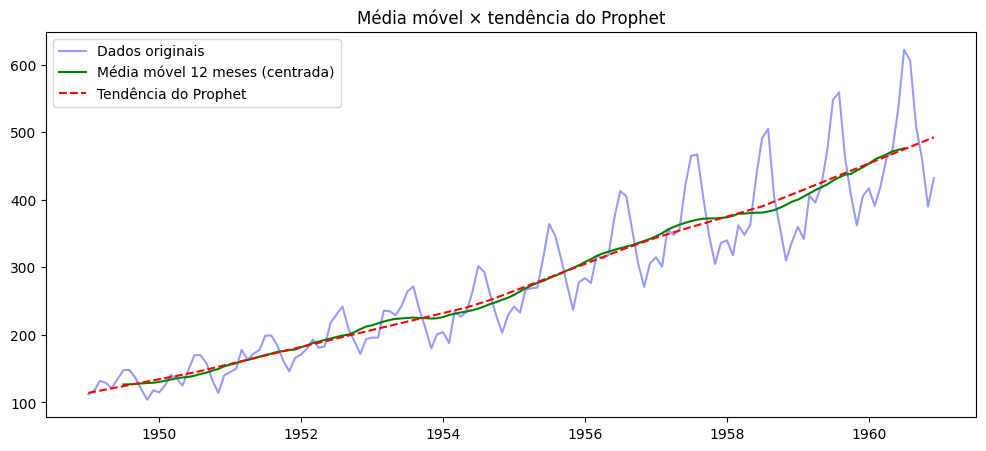

In [4]:
df_prophet = df.reset_index().rename(columns={'Month': 'ds', '#Passengers': 'y'})

modelo = Prophet(seasonality_mode='multiplicative', yearly_seasonality=True,
                 weekly_seasonality=False, daily_seasonality=False)
modelo.fit(df_prophet)
ajuste = modelo.predict(df_prophet[['ds']])

plt.figure(figsize=(12, 5))
plt.plot(df, color='blue', alpha=0.4, label='Dados originais')
plt.plot(df.rolling(12, center=True).mean(), color='green', label='Média móvel 12 meses (centrada)')
plt.plot(ajuste.ds, ajuste.trend, color='red', linestyle='--', label='Tendência do Prophet')
plt.title('Média móvel × tendência do Prophet')
plt.legend()
plt.show()

As duas curvas contam a mesma história. As diferenças importantes são:

| | Média móvel | Tendência do Prophet |
|---|---|---|
| Início e fim da série | Perde $N/2$ meses em cada ponta (centrada) | Cobre a série inteira |
| Sazonalidade | Precisa escolher $N$ igual ao período para cancelá-la | Modelada separadamente |
| Futuro | Não existe valor depois do último dado | É uma função do tempo: pode ser **projetada** |

## Média móvel como previsão

A média móvel também pode ser usada como um modelo de previsão bem simples: **a previsão para os próximos meses é a média dos últimos $N$ meses**.

É um bom ponto de partida (*baseline*), mas tem duas limitações claras:
- a previsão é uma **linha reta**: não captura a sazonalidade;
- ela fica **atrasada** quando há tendência, porque olha só para o passado.

Previsão por média móvel (12 meses) para 1961: 476 passageiros por mês
Média da previsão do Prophet para 1961: 517 passageiros por mês


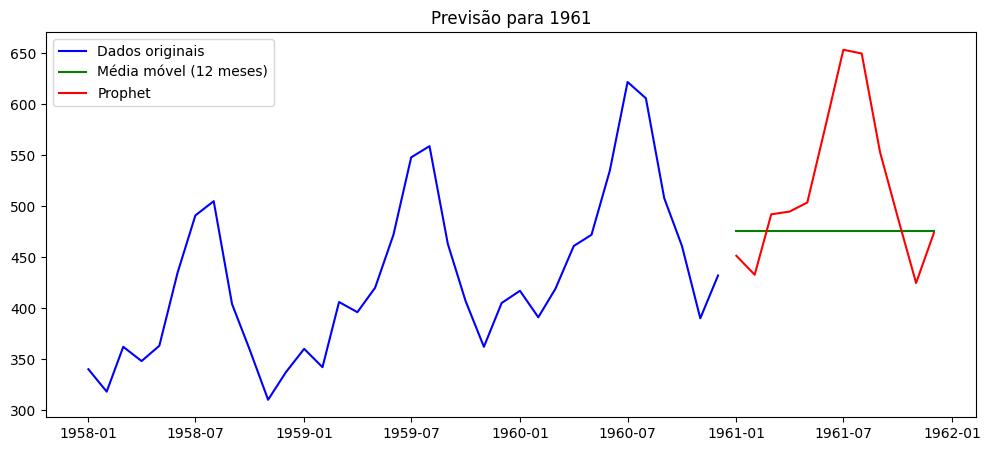

In [5]:
N = 12
previsao_mm = df['#Passengers'].iloc[-N:].mean()
print(f'Previsão por média móvel ({N} meses) para 1961: {previsao_mm:.0f} passageiros por mês')

futuro = modelo.make_future_dataframe(periods=12, freq='MS')
previsao = modelo.predict(futuro).tail(12)
print(f'Média da previsão do Prophet para 1961: {previsao.yhat.mean():.0f} passageiros por mês')

plt.figure(figsize=(12, 5))
plt.plot(df.loc['1958':], color='blue', label='Dados originais')
plt.plot(previsao.ds, [previsao_mm] * 12, color='green', label=f'Média móvel ({N} meses)')
plt.plot(previsao.ds, previsao.yhat, color='red', label='Prophet')
plt.title('Previsão para 1961')
plt.legend()
plt.show()

A média móvel prevê o mesmo valor para todos os meses: subestima muito o pico de julho e agosto e superestima os meses de baixa. Além disso, fica abaixo do nível médio previsto pelo Prophet, porque olha só para o ano anterior enquanto a série continua crescendo. O Prophet projeta a tendência e reproduz o padrão sazonal. Na próxima parte da aula vamos construir e avaliar modelos com o Prophet.